### Required Assignment 5.1: Will the Customer Accept the Coupon?

**Context**

Imagine driving through town and a coupon is delivered to your cell phone for a restaurant near where you are driving. Would you accept that coupon and take a short detour to the restaurant? Would you accept the coupon but use it on a subsequent trip? Would you ignore the coupon entirely? What if the coupon was for a bar instead of a restaurant? What about a coffee house? Would you accept a bar coupon with a minor passenger in the car? What about if it was just you and your partner in the car? Would weather impact the rate of acceptance? What about the time of day?

Obviously, proximity to the business is a factor on whether the coupon is delivered to the driver or not, but what are the factors that determine whether a driver accepts the coupon once it is delivered to them? How would you determine whether a driver is likely to accept a coupon?

**Overview**

The goal of this project is to use what you know about visualizations and probability distributions to distinguish between customers who accepted a driving coupon versus those that did not.

**Data**

This data comes to us from the UCI Machine Learning repository and was collected via a survey on Amazon Mechanical Turk. The survey describes different driving scenarios including the destination, current time, weather, passenger, etc., and then ask the person whether he will accept the coupon if he is the driver. Answers that the user will drive there ‘right away’ or ‘later before the coupon expires’ are labeled as ‘Y = 1’ and answers ‘no, I do not want the coupon’ are labeled as ‘Y = 0’.  There are five different types of coupons -- less expensive restaurants (under \$20), coffee houses, carry out & take away, bar, and more expensive restaurants (\$20 - $50).

**Deliverables**

Your final product should be a brief report that highlights the differences between customers who did and did not accept the coupons.  To explore the data you will utilize your knowledge of plotting, statistical summaries, and visualization using Python. You will publish your findings in a public facing github repository as your first portfolio piece.





### Data Description
Keep in mind that these values mentioned below are average values.

The attributes of this data set include:
1. User attributes
    -  Gender: male, female
    -  Age: below 21, 21 to 25, 26 to 30, etc.
    -  Marital Status: single, married partner, unmarried partner, or widowed
    -  Number of children: 0, 1, or more than 1
    -  Education: high school, bachelors degree, associates degree, or graduate degree
    -  Occupation: architecture & engineering, business & financial, etc.
    -  Annual income: less than \\$12500, \\$12500 - \\$24999, \\$25000 - \\$37499, etc.
    -  Number of times that he/she goes to a bar: 0, less than 1, 1 to 3, 4 to 8 or greater than 8
    -  Number of times that he/she buys takeaway food: 0, less than 1, 1 to 3, 4 to 8 or greater
    than 8
    -  Number of times that he/she goes to a coffee house: 0, less than 1, 1 to 3, 4 to 8 or
    greater than 8
    -  Number of times that he/she eats at a restaurant with average expense less than \\$20 per
    person: 0, less than 1, 1 to 3, 4 to 8 or greater than 8
    -  Number of times that he/she goes to a bar: 0, less than 1, 1 to 3, 4 to 8 or greater than 8
    

2. Contextual attributes
    - Driving destination: home, work, or no urgent destination
    - Location of user, coupon and destination: we provide a map to show the geographical
    location of the user, destination, and the venue, and we mark the distance between each
    two places with time of driving. The user can see whether the venue is in the same
    direction as the destination.
    - Weather: sunny, rainy, or snowy
    - Temperature: 30F, 55F, or 80F
    - Time: 10AM, 2PM, or 6PM
    - Passenger: alone, partner, kid(s), or friend(s)


3. Coupon attributes
    - time before it expires: 2 hours or one day

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

sns.set_theme(style='whitegrid', palette='deep')
plt.rcParams.update({'figure.figsize': (9, 5), 'axes.titlesize': 13})


### Problems

Use the prompts below to get started with your data analysis.  

1. Read in the `coupons.csv` file.




In [2]:
# The notebook lives in notebooks/; the source dataset lives in ../data/.
# When running Jupyter from the project root, use data/ instead.
from pathlib import Path

csv_path = Path('../data/coupons.csv')
if not csv_path.exists():
    csv_path = Path('data/coupons.csv')
data = pd.read_csv(csv_path)
print(f'Dataset: {data.shape[0]:,} survey scenarios and {data.shape[1]} columns')

Dataset: 12,684 survey scenarios and 26 columns


In [3]:
data.head()

,destination,passanger,weather,temperature,time,coupon,expiration,gender,age,maritalStatus,has_children,education,occupation,income,car,Bar,CoffeeHouse,CarryAway,RestaurantLessThan20,Restaurant20To50,toCoupon_GEQ5min,toCoupon_GEQ15min,toCoupon_GEQ25min,direction_same,direction_opp,Y
0,No Urgent Place,Alone,Sunny,55,2PM,Restaurant(<20),1d,Female,21,Unmarried partner,1,Some college - no degree,Unemployed,$37500 - $49999,NaN,never,never,NaN,4~8,1~3,1,0,0,0,1,1
1,No Urgent Place,Friend(s),Sunny,80,10AM,Coffee House,2h,Female,21,Unmarried partner,1,Some college - no degree,Unemployed,$37500 - $49999,NaN,never,never,NaN,4~8,1~3,1,0,0,0,1,0
2,No Urgent Place,Friend(s),Sunny,80,10AM,Carry out & Take away,2h,Female,21,Unmarried partner,1,Some college - no degree,Unemployed,$37500 - $49999,NaN,never,never,NaN,4~8,1~3,1,1,0,0,1,1
3,No Urgent Place,Friend(s),Sunny,80,2PM,Coffee House,2h,Female,21,Unmarried partner,1,Some college - no degree,Unemployed,$37500 - $49999,NaN,never,never,NaN,4~8,1~3,1,1,0,0,1,0
4,No Urgent Place,Friend(s),Sunny,80,2PM,Coffee House,1d,Female,21,Unmarried partner,1,Some college - no degree,Unemployed,$37500 - $49999,NaN,never,never,NaN,4~8,1~3,1,1,0,0,1,0


2. Investigate the dataset for missing or problematic data.

In [4]:
print('Column types and non-null counts:')
data.info()
missing = data.isna().sum().sort_values(ascending=False)
missing_table = pd.DataFrame({'missing_count': missing, 'missing_percent': (missing / len(data) * 100).round(2)})
display(missing_table[missing_table.missing_count > 0])
print(f'Exact duplicate rows: {data.duplicated().sum():,}')
print('Target values:', data['Y'].value_counts().to_dict())

Column types and non-null counts:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12684 entries, 0 to 12683
Data columns (total 26 columns):
 #   Column                Non-Null Count  Dtype 
---  ------                --------------  ----- 
 0   destination           12684 non-null  object
 1   passanger             12684 non-null  object
 2   weather               12684 non-null  object
 3   temperature           12684 non-null  int64 
 4   time                  12684 non-null  object
 5   coupon                12684 non-null  object
 6   expiration            12684 non-null  object
 7   gender                12684 non-null  object
 8   age                   12684 non-null  object
 9   maritalStatus         12684 non-null  object
 10  has_children          12684 non-null  int64 
 11  education             12684 non-null  object
 12  occupation            12684 non-null  object
 13  income                12684 non-null  object
 14  car                   108 non-null    object
 15  Ba

,missing_count,missing_percent
car,12576,99.15
CoffeeHouse,217,1.71
Restaurant20To50,189,1.49
CarryAway,151,1.19
RestaurantLessThan20,130,1.02
Bar,107,0.84


Exact duplicate rows: 74
Target values: {1: 7210, 0: 5474}


3. Decide what to do about your missing data -- drop, replace, other...

In [5]:
# The 'car' column is missing in nearly all records and is not useful for this EDA.
# Preserve survey rows; do not drop rows solely because a frequency field is missing.
# Fill the small number of missing visit-frequency responses as 'Unknown'.
# 'Unknown' is excluded from definite frequency-based comparisons.
frequency_columns = ['Bar', 'CoffeeHouse', 'CarryAway',
                     'RestaurantLessThan20', 'Restaurant20To50']
clean_data = data.drop(columns=['car']).copy()
for col in frequency_columns:
    clean_data[col] = clean_data[col].fillna('Unknown')
print('Original observations:', len(data))
print('Retained observations:', len(clean_data))
print('Missing values remaining:', int(clean_data.isna().sum().sum()))
print('Exact duplicates retained: survey responses lack a unique respondent ID; identical rows may be valid.')

Original observations: 12684
Retained observations: 12684
Missing values remaining: 0
Exact duplicates retained: survey responses lack a unique respondent ID; identical rows may be valid.


4. What proportion of the total observations chose to accept the coupon?



In [6]:
overall_acceptance = clean_data['Y'].mean()
print(f'Overall acceptance: {overall_acceptance:.2%} ({clean_data.Y.sum():,} of {len(clean_data):,})')
display(clean_data['Y'].value_counts().rename(index={0:'Rejected', 1:'Accepted'}).to_frame('Observations'))

Overall acceptance: 56.84% (7,210 of 12,684)


,Observations
Y,
Accepted,7210
Rejected,5474


5. Use a bar plot to visualize the `coupon` column.

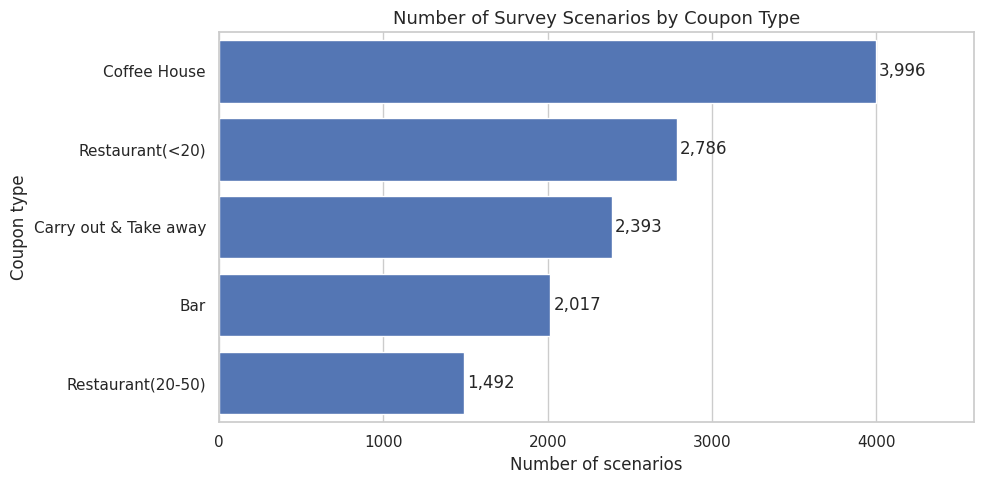

In [7]:
fig, ax = plt.subplots(figsize=(10, 5))
order = clean_data['coupon'].value_counts().index
sns.countplot(data=clean_data, y='coupon', order=order, color='#4472C4', ax=ax)
ax.set(title='Number of Survey Scenarios by Coupon Type', xlabel='Number of scenarios', ylabel='Coupon type')
for bar_patch in ax.patches:
    ax.text(bar_patch.get_width()+18, bar_patch.get_y()+bar_patch.get_height()/2,
            f'{int(bar_patch.get_width()):,}', va='center')
ax.set_xlim(0, clean_data['coupon'].value_counts().max()*1.15)
plt.tight_layout()
plt.show()

6. Use a histogram to visualize the temperature column.

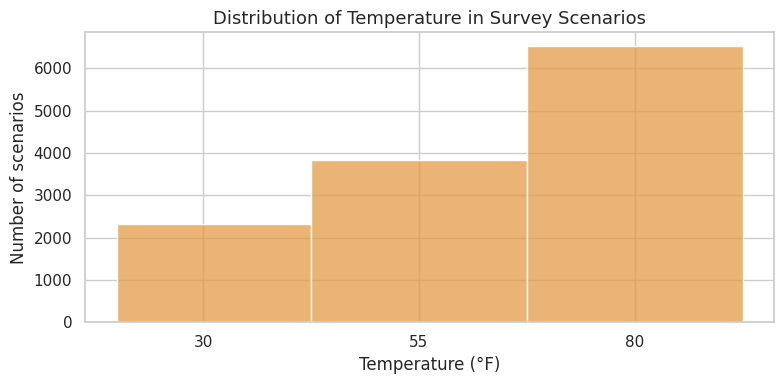

In [8]:
fig, ax = plt.subplots(figsize=(8, 4))
sns.histplot(data=clean_data, x='temperature', bins=[20, 42.5, 67.5, 92.5], color='#E49B46', ax=ax)
ax.set(title='Distribution of Temperature in Survey Scenarios', xlabel='Temperature (°F)', ylabel='Number of scenarios')
ax.set_xticks([30,55,80])
plt.tight_layout()
plt.show()

**Investigating the Bar Coupons**

Now, we will lead you through an exploration of just the bar related coupons.  

1. Create a new `DataFrame` that contains just the bar coupons.


In [9]:
bar_data = clean_data.loc[clean_data['coupon'].eq('Bar')].copy()
print(f'Bar coupon scenarios: {len(bar_data):,}')
display(bar_data.head())

Bar coupon scenarios: 2,017


,destination,passanger,weather,temperature,time,coupon,expiration,gender,age,maritalStatus,has_children,education,occupation,income,Bar,CoffeeHouse,CarryAway,RestaurantLessThan20,Restaurant20To50,toCoupon_GEQ5min,toCoupon_GEQ15min,toCoupon_GEQ25min,direction_same,direction_opp,Y
9,No Urgent Place,Kid(s),Sunny,80,10AM,Bar,1d,Female,21,Unmarried partner,1,Some college - no degree,Unemployed,$37500 - $49999,never,never,Unknown,4~8,1~3,1,1,0,0,1,0
13,Home,Alone,Sunny,55,6PM,Bar,1d,Female,21,Unmarried partner,1,Some college - no degree,Unemployed,$37500 - $49999,never,never,Unknown,4~8,1~3,1,0,0,1,0,1
17,Work,Alone,Sunny,55,7AM,Bar,1d,Female,21,Unmarried partner,1,Some college - no degree,Unemployed,$37500 - $49999,never,never,Unknown,4~8,1~3,1,1,1,0,1,0
24,No Urgent Place,Friend(s),Sunny,80,10AM,Bar,1d,Male,21,Single,0,Bachelors degree,Architecture & Engineering,$62500 - $74999,never,less1,4~8,4~8,less1,1,0,0,0,1,1
35,Home,Alone,Sunny,55,6PM,Bar,1d,Male,21,Single,0,Bachelors degree,Architecture & Engineering,$62500 - $74999,never,less1,4~8,4~8,less1,1,0,0,1,0,1


2. What proportion of bar coupons were accepted?


In [10]:
bar_acceptance = bar_data.Y.mean()
print(f'Bar coupon acceptance: {bar_acceptance:.2%} ({bar_data.Y.sum():,} / {len(bar_data):,})')

Bar coupon acceptance: 41.00% (827 / 2,017)


3. Compare the acceptance rate between those who went to a bar 3 or fewer times a month to those who went more.


In [11]:
# >3 visits = 4~8 or gt8; <=3 visits = never, less1, or 1~3.
# Unknown frequency is excluded from both groups rather than misclassified.
bar_le3 = bar_data['Bar'].isin(['never','less1','1~3'])
bar_gt3 = bar_data['Bar'].isin(['4~8','gt8'])
comparison_3 = pd.DataFrame({
    'Group': ['3 or fewer visits/month', 'More than 3 visits/month'],
    'Count': [bar_le3.sum(), bar_gt3.sum()],
    'Acceptance rate': [bar_data.loc[bar_le3,'Y'].mean(), bar_data.loc[bar_gt3,'Y'].mean()]
})
display(comparison_3.style.format({'Acceptance rate':'{:.1%}'}))
print('Unknown visit-frequency rows excluded:', (~(bar_le3|bar_gt3)).sum())

,Group,Count,Acceptance rate
0,3 or fewer visits/month,1797,37.1%
1,More than 3 visits/month,199,76.9%


Unknown visit-frequency rows excluded: 21


4. Compare the acceptance rate between drivers who go to a bar more than once a month and are over the age of 25 to the all others.  Is there a difference?


In [12]:
# More than once/month means categories 1~3, 4~8, gt8.
# Ages 26 and above are over 25; ages '21' and 'below21' are not.
bar_gt1 = bar_data['Bar'].isin(['1~3','4~8','gt8'])
age_over25 = ~bar_data['age'].isin(['below21','21'])
condition_age = bar_gt1 & age_over25
age_comparison = pd.DataFrame({
    'Group':['Bar >1/month and age >25','All other bar coupon scenarios'],
    'Count':[condition_age.sum(), (~condition_age).sum()],
    'Acceptance rate':[bar_data.loc[condition_age,'Y'].mean(),bar_data.loc[~condition_age,'Y'].mean()]
})
display(age_comparison.style.format({'Acceptance rate':'{:.1%}'}))

,Group,Count,Acceptance rate
0,Bar >1/month and age >25,420,69.5%
1,All other bar coupon scenarios,1597,33.5%


5. Use the same process to compare the acceptance rate between drivers who go to bars more than once a month and had passengers that were not a kid and had occupations other than farming, fishing, or forestry.


In [13]:
# Exclude Kid(s) passengers and the specified occupation.
condition_passenger = (bar_gt1 & bar_data['passanger'].ne('Kid(s)') &
                       bar_data['occupation'].ne('Farming Fishing & Forestry'))
passenger_comparison = pd.DataFrame({
    'Group':['Bar >1/month, no kid passenger, not farming/fishing/forestry', 'All other bar coupon scenarios'],
    'Count':[condition_passenger.sum(), (~condition_passenger).sum()],
    'Acceptance rate':[bar_data.loc[condition_passenger,'Y'].mean(),bar_data.loc[~condition_passenger,'Y'].mean()]
})
display(passenger_comparison.style.format({'Acceptance rate':'{:.1%}'}))

,Group,Count,Acceptance rate
0,"Bar >1/month, no kid passenger, not farming/fishing/forestry",551,71.3%
1,All other bar coupon scenarios,1466,29.6%


6. Compare the acceptance rates between those drivers who:

- go to bars more than once a month, had passengers that were not a kid, and were not widowed *OR*
- go to bars more than once a month and are under the age of 30 *OR*
- go to cheap restaurants more than 4 times a month and income is less than 50K.



,Group,Count,Acceptance rate
0,"Rule 1: bar >1, no kids, not widowed",551,71.3%
1,"Rule 2: bar >1, age under 30",345,72.2%
2,"Rule 3: cheap restaurants >4, income <50K",344,45.3%
3,Any of the three rules (OR),776,58.9%
4,None of the three rules,1241,29.8%


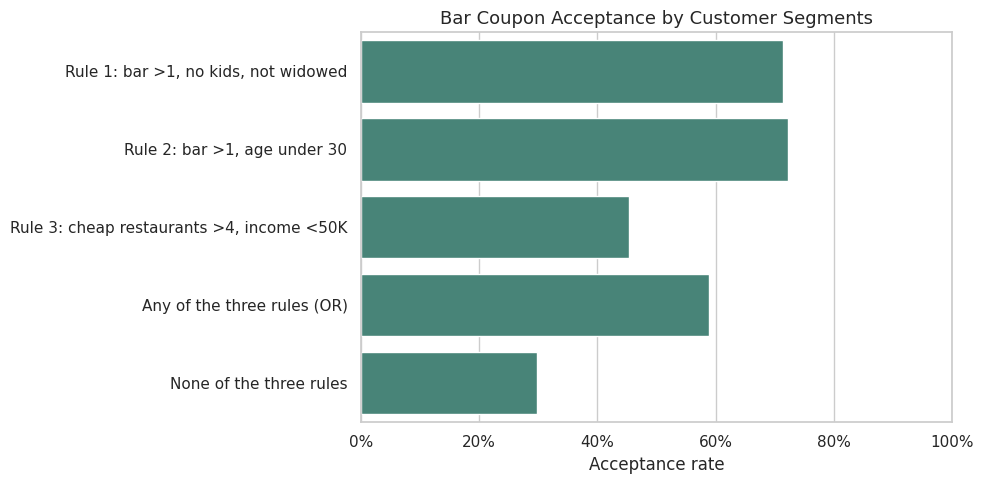

In [14]:
# The three rules are examined separately and as an OR-combination.
# The wording 'under age 30' includes below21, 21, and 26.
# 'Less than 50K' includes all four brackets below $50,000.
under30 = bar_data['age'].isin(['below21','21','26'])
under50k = bar_data['income'].isin(['Less than $12500','$12500 - $24999',
                                   '$25000 - $37499','$37500 - $49999'])
cheap_rest_gt4 = bar_data['RestaurantLessThan20'].isin(['4~8','gt8'])
rule1 = bar_gt1 & bar_data['passanger'].ne('Kid(s)') & bar_data['maritalStatus'].ne('Widowed')
rule2 = bar_gt1 & under30
rule3 = cheap_rest_gt4 & under50k
rule_any = rule1 | rule2 | rule3
rules = {'Rule 1: bar >1, no kids, not widowed':rule1,
         'Rule 2: bar >1, age under 30':rule2,
         'Rule 3: cheap restaurants >4, income <50K':rule3,
         'Any of the three rules (OR)':rule_any,
         'None of the three rules':~rule_any}
rule_table = pd.DataFrame([
    {'Group':label,'Count':int(mask.sum()),'Acceptance rate':bar_data.loc[mask,'Y'].mean()}
    for label,mask in rules.items()
])
display(rule_table.style.format({'Acceptance rate':'{:.1%}'}))
fig,ax=plt.subplots(figsize=(10,5))
sns.barplot(data=rule_table, y='Group', x='Acceptance rate', color='#3E8E7E', ax=ax)
ax.set(title='Bar Coupon Acceptance by Customer Segments',xlabel='Acceptance rate',ylabel='')
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v,_:f'{v:.0%}'))
ax.set_xlim(0,1)
plt.tight_layout();plt.show()

7.  Based on these observations, what do you hypothesize about drivers who accepted the bar coupons?

In [15]:
print('Hypothesis: Customers who already visit bars regularly are more likely to accept bar coupons.')
print('Age, passenger context, and restaurant habits may further differentiate acceptance.')
print('These are descriptive survey associations, not proof of causation.')
print('See the comparisons and subgroup sizes above before targeting any segment.')

Hypothesis: Customers who already visit bars regularly are more likely to accept bar coupons.
Age, passenger context, and restaurant habits may further differentiate acceptance.
These are descriptive survey associations, not proof of causation.
See the comparisons and subgroup sizes above before targeting any segment.


### Independent Investigation

Using the bar coupon example as motivation, you are to explore one of the other coupon groups and try to determine the characteristics of passengers who accept the coupons.  

In [16]:
# Independent investigation: Coffee House coupons
coffee_data = clean_data.loc[clean_data.coupon.eq('Coffee House')].copy()
print(f'Coffee House scenarios: {len(coffee_data):,}')
print(f'Coffee House acceptance: {coffee_data.Y.mean():.2%}')

# Compare by prior coffee-house visit frequency.
coffee_order = ['never','less1','1~3','4~8','gt8','Unknown']
coffee_frequency = (coffee_data.groupby('CoffeeHouse', observed=True)['Y']
                    .agg(acceptance_rate='mean',count='size')
                    .reindex(coffee_order).dropna(subset=['count']))
display(coffee_frequency.style.format({'acceptance_rate':'{:.1%}', 'count':'{:.0f}'}))

Coffee House scenarios: 3,996
Coffee House acceptance: 49.92%


,acceptance_rate,count
CoffeeHouse,,
never,18.9%,927
less1,48.2%,1075
1~3,64.8%,1042
4~8,68.6%,538
gt8,65.8%,342
Unknown,45.8%,72


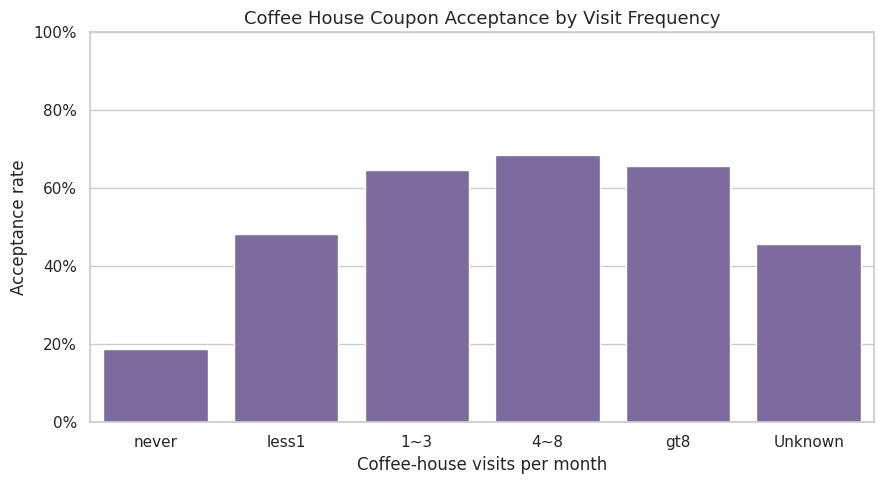

In [17]:
fig,ax=plt.subplots(figsize=(9,5))
sns.barplot(data=coffee_frequency.reset_index(),x='CoffeeHouse',y='acceptance_rate',color='#7B61A8',ax=ax)
ax.set(title='Coffee House Coupon Acceptance by Visit Frequency',xlabel='Coffee-house visits per month',ylabel='Acceptance rate')
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v,_:f'{v:.0%}'))
ax.set_ylim(0,1)
plt.tight_layout();plt.show()

By time of day:


,acceptance_rate,count
time,,
7AM,44.6%,913
10AM,64.1%,899
2PM,54.8%,794
6PM,41.3%,1093
10PM,42.4%,297


By expiration:


,acceptance_rate,count
expiration,,
1d,58.4%,1769
2h,43.2%,2227


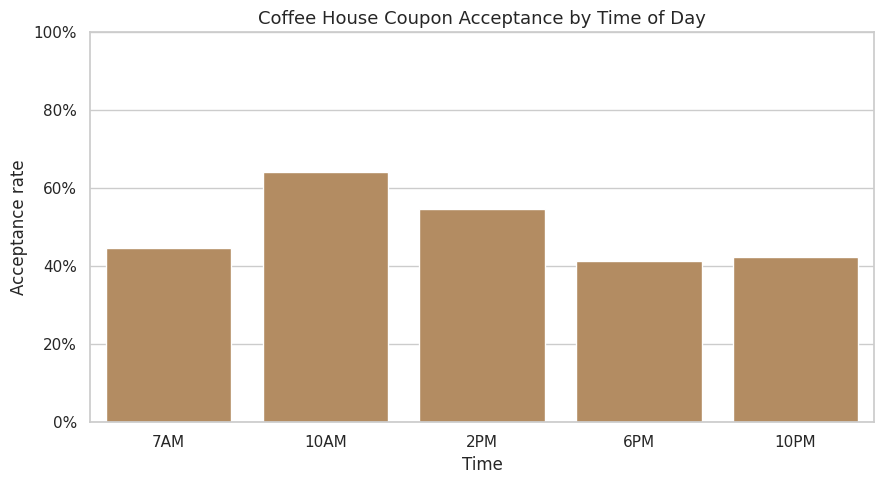

In [18]:
# Examine the context: time of day and coupon expiration.
coffee_time = (coffee_data.groupby('time')['Y'].agg(acceptance_rate='mean',count='size')
               .reindex(['7AM','10AM','2PM','6PM','10PM']))
coffee_expiration = coffee_data.groupby('expiration')['Y'].agg(acceptance_rate='mean',count='size')
print('By time of day:')
display(coffee_time.style.format({'acceptance_rate':'{:.1%}'}))
print('By expiration:')
display(coffee_expiration.style.format({'acceptance_rate':'{:.1%}'}))
fig,ax=plt.subplots(figsize=(9,5))
sns.barplot(data=coffee_time.reset_index(),x='time',y='acceptance_rate',color='#C08D55',ax=ax)
ax.set(title='Coffee House Coupon Acceptance by Time of Day',xlabel='Time',ylabel='Acceptance rate')
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v,_:f'{v:.0%}'))
ax.set_ylim(0,1)
plt.tight_layout();plt.show()

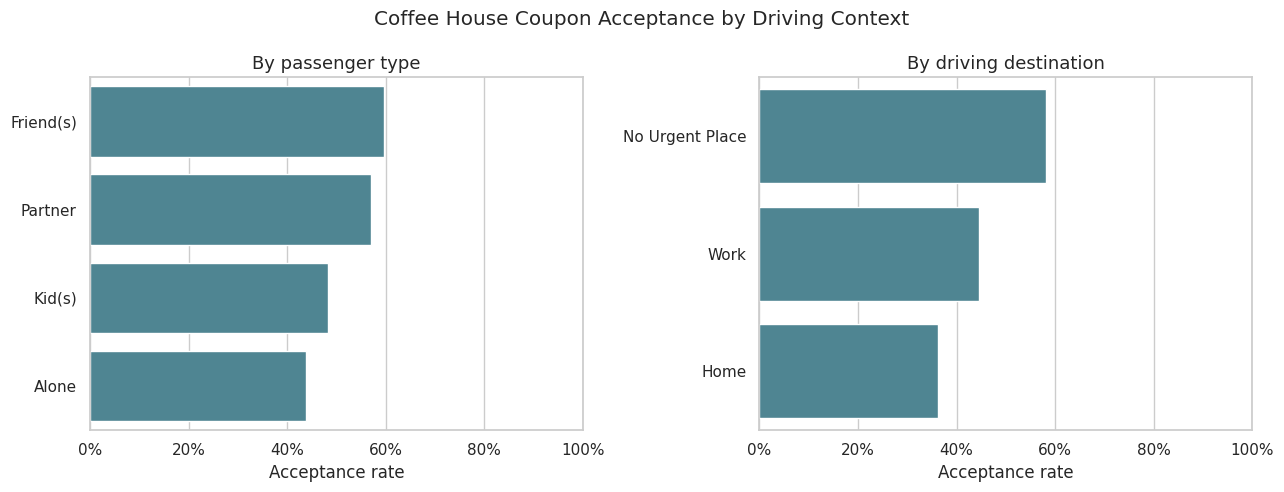

In [19]:
# Look at companion type and destination for further context.
fig,axes=plt.subplots(1,2,figsize=(13,5))
for ax,col,title in zip(axes,['passanger','destination'],
                        ['By passenger type','By driving destination']):
    summary=coffee_data.groupby(col)['Y'].mean().sort_values(ascending=False)
    sns.barplot(x=summary.values,y=summary.index,color='#448C9D',ax=ax)
    ax.set(title=title,xlabel='Acceptance rate',ylabel='')
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v,_:f'{v:.0%}'))
    ax.set_xlim(0,1)
plt.suptitle('Coffee House Coupon Acceptance by Driving Context')
plt.tight_layout();plt.show()

In [20]:
# Actionable descriptive findings: compare regular coffee visitors with others.
regular_coffee = coffee_data['CoffeeHouse'].isin(['1~3','4~8','gt8'])
coffee_segment_table = pd.DataFrame({
    'Segment':['Visits coffee houses at least 1/month','Less frequent or unknown visits'],
    'Count':[regular_coffee.sum(),(~regular_coffee).sum()],
    'Acceptance rate':[coffee_data.loc[regular_coffee,'Y'].mean(),
                       coffee_data.loc[~regular_coffee,'Y'].mean()]
})
display(coffee_segment_table.style.format({'Acceptance rate':'{:.1%}'}))
print('Recommendations:')
print('1. Test coffee coupons with customers who already visit coffee houses.')
print('2. Test delivery at times with higher observed acceptance, while checking group sizes.')
print('3. Use randomized experiments before claiming these segments cause better results.')
print('4. The survey measures stated acceptance, not observed redemption or revenue.')

,Segment,Count,Acceptance rate
0,Visits coffee houses at least 1/month,1922,66.0%
1,Less frequent or unknown visits,2074,35.0%


Recommendations:
1. Test coffee coupons with customers who already visit coffee houses.
2. Test delivery at times with higher observed acceptance, while checking group sizes.
3. Use randomized experiments before claiming these segments cause better results.
4. The survey measures stated acceptance, not observed redemption or revenue.


## Inferential Statistics: Coffee House Visit Frequency and Coupon Acceptance

**Research question:** Is prior Coffee House visit frequency associated with coupon acceptance? Compare respondents who report visiting at least once a month (`1~3`, `4~8`, `gt8`) against all other Coffee House respondents (`never`, `less1`, or missing). The missing-frequency records are grouped with the comparison group for consistency with the descriptive analysis, but this limits interpretation.

- **Null hypothesis (H₀):** Coupon acceptance is independent of the two visit-frequency groups (equal underlying acceptance probabilities).
- **Alternative hypothesis (H₁):** Acceptance and visit-frequency group are associated (the underlying probabilities differ).
- **Significance level:** α = 0.05, two-sided.
- **Methods:** Pearson chi-square test for the 2×2 contingency table, two-proportion z-test, and Wilson 95% confidence intervals for each acceptance rate. These tests assume independent observations; repeated respondents cannot be identified in this dataset.


In [21]:
# Inferential statistics for the independent Coffee House investigation.
from scipy.stats import chi2_contingency, norm

regular = coffee_data['CoffeeHouse'].isin(['1~3', '4~8', 'gt8'])
frequency_group = np.where(regular, 'At least monthly', 'Less than monthly / unknown')
contingency = pd.crosstab(pd.Series(frequency_group, index=coffee_data.index, name='Visit frequency'), coffee_data['Y'])
contingency = contingency.reindex(index=['At least monthly', 'Less than monthly / unknown'], columns=[0, 1], fill_value=0)
contingency.columns = ['Rejected', 'Accepted']
print('Observed counts (Coffee House coupons):')
display(contingency)

chi2, p_chi, dof, expected = chi2_contingency(contingency, correction=False)
counts = contingency['Accepted'].to_numpy()
totals = contingency.sum(axis=1).to_numpy()
rates = counts / totals

def wilson_interval(successes, n, confidence=0.95):
    # Wilson score interval behaves better than the simple normal approximation.
    z = norm.ppf(1 - (1 - confidence) / 2)
    phat = successes / n
    denom = 1 + z**2 / n
    center = (phat + z**2 / (2 * n)) / denom
    margin = z * np.sqrt(phat * (1 - phat) / n + z**2 / (4 * n**2)) / denom
    return center - margin, center + margin

for label, successes, n, rate in zip(contingency.index, counts, totals, rates):
    lo, hi = wilson_interval(successes, n)
    print(f'{label}: {successes:,}/{n:,} = {rate:.1%}; Wilson 95% CI [{lo:.1%}, {hi:.1%}]')

pooled = counts.sum() / totals.sum()
se_pooled = np.sqrt(pooled * (1 - pooled) * (1 / totals[0] + 1 / totals[1]))
z_stat = (rates[0] - rates[1]) / se_pooled
p_z = 2 * norm.sf(abs(z_stat))
print(f'Absolute acceptance-rate difference: {(rates[0] - rates[1]):.1%} ({(rates[0] - rates[1]) * 100:.1f} percentage points)')
print(f'Pearson chi-square: χ²({dof}) = {chi2:.2f}, p = {p_chi:.3g}')
print(f'Two-proportion z-test: z = {z_stat:.2f}, two-sided p = {p_z:.3g}')
print('Decision at α=0.05:', 'Reject H₀ (association observed)' if p_chi < 0.05 else 'Do not reject H₀')


Observed counts (Coffee House coupons):


,Rejected,Accepted
Visit frequency,,
At least monthly,653,1269
Less than monthly / unknown,1348,726


At least monthly: 1,269/1,922 = 66.0%; Wilson 95% CI [63.9%, 68.1%]
Less than monthly / unknown: 726/2,074 = 35.0%; Wilson 95% CI [33.0%, 37.1%]
Absolute acceptance-rate difference: 31.0% (31.0 percentage points)
Pearson chi-square: χ²(1) = 383.96, p = 1.71e-85
Two-proportion z-test: z = 19.59, two-sided p = 1.71e-85
Decision at α=0.05: Reject H₀ (association observed)


### Accepted vs. Rejected: Coffee House Visit Frequency

The following 100% stacked bar chart shows **both outcomes** within each visit-frequency group. The chart complements the acceptance-rate comparison and makes the rejected share explicit. Unknown frequency is grouped with less-than-monthly visitors for consistency with the primary analysis.

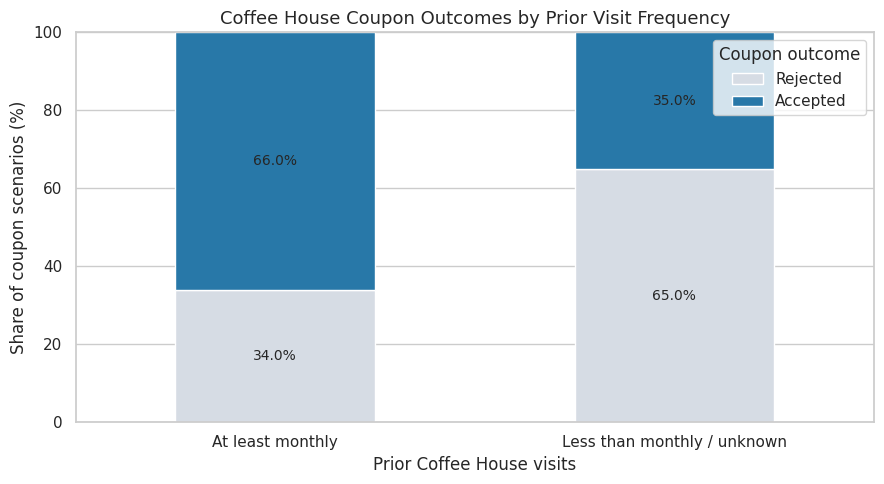

In [22]:
# Show accepted and rejected percentages together for the two visit-frequency groups.
share = contingency.div(contingency.sum(axis=1), axis=0).mul(100)
ax = share[['Rejected', 'Accepted']].plot(kind='bar', stacked=True, figsize=(9, 5), color=['#D6DCE4', '#2878A8'])
ax.set(title='Coffee House Coupon Outcomes by Prior Visit Frequency', xlabel='Prior Coffee House visits', ylabel='Share of coupon scenarios (%)', ylim=(0, 100))
ax.tick_params(axis='x', rotation=0)
for container in ax.containers:
    labels = [f'{v:.1f}%' if v >= 6 else '' for v in container.datavalues]
    ax.bar_label(container, labels=labels, label_type='center', fontsize=10)
ax.legend(title='Coupon outcome', loc='upper right')
plt.tight_layout()
plt.savefig('../outputs/coffee_accepted_vs_rejected.png', dpi=160, bbox_inches='tight')
plt.show()

### Interpretation and limitations

The chi-square and two-proportion z-tests evaluate the same two-group comparison; their p-values agree (up to rounding) for a 2×2 table without continuity correction. The 95% Wilson intervals describe uncertainty for each estimated acceptance rate, **not** the causal impact of visiting coffee houses. The comparison is observational, coupon responses may not be independent if respondents appear multiple times, and the comparison group includes unknown visit frequency. Statistical significance does not establish causality or business value. Validate the result with a controlled campaign experiment before making targeting decisions.


## Conclusions and Recommendations

**Research question:** Which surveyed customer characteristics and driving contexts are associated with accepting a coupon?

- The notebook reports the overall acceptance rate, then contrasts it with bar and coffee-house offers.
- The bar analysis tests prior bar visits, age, passenger context, occupation, and three explicitly defined segment rules.
- The independent coffee-house analysis explores visit frequency, time of day, expiration, passenger type, and destination.
- **Business actions:** pilot behavior-based coupon targeting; test timing and expiration; monitor incremental redemption and profit rather than only stated acceptance.
- **Limitations:** the observations are hypothetical survey scenarios rather than actual redemption records; the dataset does not establish causality; no unique respondent identifier is supplied; and some frequency answers are missing.

See **README.md** for a concise executive summary with numerical results.